In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import IPython.display as ipd

# Point to single_stroke_synthesis/src
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from modal2 import ModalSynthesizer
from optimize import optimize_modes
from utils import plot_acoustic_comparison

sr = 44100
synth = ModalSynthesizer(sr=sr)
print("Modal Synthesis Engine Loaded.")

Modal Synthesis Engine Loaded.


In [4]:
import json

with open("fixed_modal_frequencies.json", "r") as f:
    fixed_modes_data = json.load(f)

# 2. Select the stroke class you want to optimize
target_stroke = "hit_mid"
extracted_data = fixed_modes_data[target_stroke]

# 3. Format them into the initial modes list for the optimizer
initial_guess_modes = []
for item in extracted_data:
    # Convert the extracted dB amplitude to a linear amplitude for the starting guess
    # (e.g., 0.0 dB becomes 1.0, -6.0 dB becomes ~0.5)
    linear_amp = 10 ** (item["amp_db"] / 20.0)
    
    initial_guess_modes.append({
        'freq': item["freq"],
        'q': 20.0,              # Standard starting Q
        'amp': linear_amp,      # Smart starting amplitude based on your JSON
        'decay_mult': 15.0      # Standard starting decay
    })

Starting Full-Stroke MSSL Optimization (maxiter=20, popsize=10)...
differential_evolution step 1: f(x)= 2.1109070090696314
differential_evolution step 2: f(x)= 1.9957966416049295
differential_evolution step 3: f(x)= 1.9957966416049295
differential_evolution step 4: f(x)= 1.9957966416049295
differential_evolution step 5: f(x)= 1.9957966416049295
differential_evolution step 6: f(x)= 1.7844871238038476
differential_evolution step 7: f(x)= 1.7844871238038476
differential_evolution step 8: f(x)= 1.7844871238038476
differential_evolution step 9: f(x)= 1.7844871238038476
differential_evolution step 10: f(x)= 1.7844871238038476
differential_evolution step 11: f(x)= 1.7844871238038476
differential_evolution step 12: f(x)= 1.7819959474933897
differential_evolution step 13: f(x)= 1.7819959474933897
differential_evolution step 14: f(x)= 1.7819959474933897
differential_evolution step 15: f(x)= 1.7819959474933897
differential_evolution step 16: f(x)= 1.7819959474933897
differential_evolution step 17

[{'freq': 592.16, 'q': np.float64(114.2891278738319), 'amp': np.float64(6.882553640143604), 'decay_mult': np.float64(131.33141770140108)}, {'freq': 290.7, 'q': np.float64(3.355379634162233), 'amp': np.float64(1.9352300765542028), 'decay_mult': np.float64(22.246202387876522)}, {'freq': 430.66, 'q': np.float64(10.163869016308041), 'amp': np.float64(1.457294230609714), 'decay_mult': np.float64(9.295871479179297)}, {'freq': 753.66, 'q': np.float64(101.71131986382699), 'amp': np.float64(4.7688517860064605), 'decay_mult': np.float64(171.18037122013038)}, {'freq': 656.76, 'q': np.float64(102.07587981245292), 'amp': np.float64(8.505321003290264), 'decay_mult': np.float64(136.3283013348098)}, {'freq': 1205.86, 'q': np.float64(38.452861667083546), 'amp': np.float64(2.0983937951025666), 'decay_mult': np.float64(108.89908908185969)}, {'freq': 904.39, 'q': np.float64(59.55499352962276), 'amp': np.float64(6.782256780003967), 'decay_mult': np.float64(67.52879958010301)}, {'freq': 1367.36, 'q': np.flo

/home/dibahadie/Projects/Research/Tonbak-Sound-Analysis-and-Synthesis/single_stroke_synthesis/src/utils.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


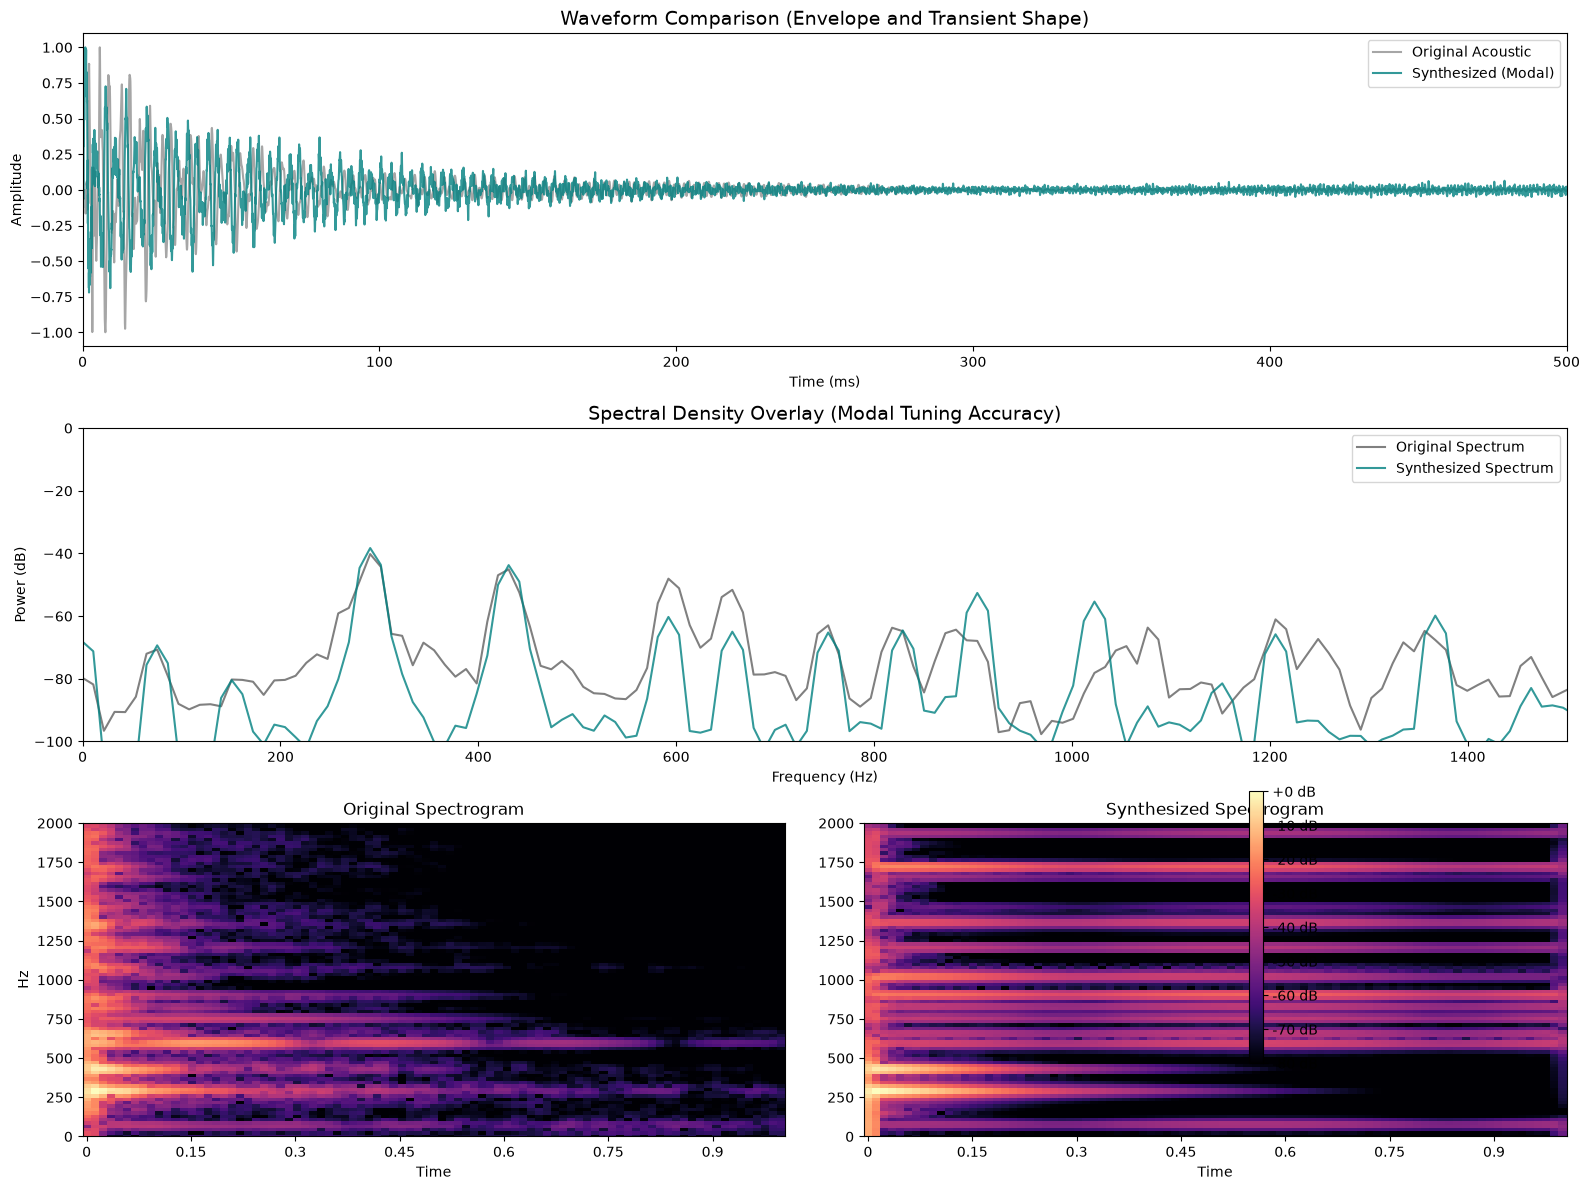

In [3]:
stroke = 'hit_mid'
original_audio_path = f"../../single_stroke_analysis/data/raw/{stroke}/GIO_MEE_tombak_{stroke}.wav"
original_audio, sr = librosa.load(original_audio_path, sr=44100)
optimized_modes, optimized_audio = optimize_modes(
    target_audio=original_audio, 
    initial_modes=initial_guess_modes, 
    synth_instance=synth, 
    sr=sr, 
    target_duration=1.0, 
    max_iter=20
)
display(ipd.Audio(optimized_audio, rate=sr))
print(optimized_modes)
plot_acoustic_comparison(original_audio, optimized_audio)